# D5 – Mini-projet : une série temporelle

**Python numérique – devoir n° 5 – à rendre pour le dimanche 18 octobre 2026, 23 h 59** (la séance 6 est le mardi 20)

Bienvenue dans votre cinquième devoir ! Nous allons y mettre en œuvre les notions vues en séance 5 : `to_datetime`, `DatetimeIndex`, la sélection par dates, `resample`, `rolling`, `df.plot` et les figures à plusieurs sous-graphiques avec `matplotlib`. C'est aussi un mini-projet : la dernière partie est ouverte, et c'est vous qui choisissez la question à laquelle répondre.

Durée indicative : 1 h 30.

````{admonition} Consignes de rendu
:class: important

* Ce notebook reste dans le dossier `D5/` de votre dépôt `pe-homework` (celui que le zip du sujet a créé en se dézippant), avec ses figures à côté, puis il doit être **commité et poussé** (`git add`, `git commit`, `git push`) avant la deadline. Attention, c'est la **date du commit** qui fait foi, pas celle du push ; le nom du fichier, lui, n'a pas d'importance (`sujet.ipynb` convient très bien). Le dossier `data/` livré avec le sujet reste lui aussi dans `D5/` : `git add D5` embarque tout le dossier, et c'est très bien ainsi (il ne pèse que quelques kilo-octets).
* Juste avant de rendre, **pensez à ré-exécuter toutes les cellules** via *Kernel → Restart Kernel and Run All Cells* : toutes doivent s'exécuter dans l'ordre et sans erreur. En effet, un notebook qui plante à mi-chemin sera corrigé jusqu'à l'erreur…
* Le notebook lit les données dans `data/comptage-velos.csv` (chemin relatif) ; la figure `serie.png` est quant à elle écrite dans le dossier du notebook.
* Les cellules `# votre code` sont à compléter ; vous pouvez ajouter autant de cellules que vous le souhaitez. Les cellules de test (`assert`) sont là pour vous aider : si elles passent sans erreur, c'est bon signe. Ne les modifiez pas !
* Répondez aux questions "en français" dans une cellule *Markdown*, en deux ou trois phrases. Dans ce devoir, la rédaction compte autant que le code.
````

````{admonition} Ce qui est autorisé
:class: note

* La documentation de `pandas` / `matplotlib`, les notebooks du cours, vos notes.
* Les assistants IA sont tolérés, avec la règle habituelle : **vous devez être capable d'expliquer chaque ligne que vous rendez**, et je pourrai vous demander de le faire à l'oral en séance. Le devoir est individuel.
* En revanche, pas de boucle `for` sur les lignes de la série : tout se fait avec les opérations `pandas`.
````

````{admonition} Les données
:class: warning

`data/comptage-velos.csv` contient le nombre de vélos comptés chaque jour par un compteur automatique installé sur une piste cyclable parisienne, du 1er janvier 2023 au 31 décembre 2024 : une colonne `date` (texte `AAAA-MM-JJ`) et une colonne `comptage`, séparées par `;`.

Attention, **ces données sont simulées** : je les ai produites avec le script `data/generate.py`, en fixant la graine afin que tout le monde travaille sur les mêmes valeurs. Vous pouvez le lire, mais seulement *après* avoir fait le devoir ! Elles ont cependant l'allure de vraies données de comptage, défauts compris : le fichier n'est pas trié, certaines lignes sont en double, certains jours n'ont pas de mesure, et le capteur a eu au moins deux ratés. Ainsi, comme dans la vraie vie, vous allez d'abord nettoyer, puis analyser.
````

## Barème

| Exercice | Contenu | Points |
|---|---|---|
| 1 | Chargement, index temporel, diagnostic et nettoyage | 6 |
| 2 | Rééchantillonnage (`resample`) et lissage (`rolling`) | 4 |
| 3 | Profils hebdomadaire et mensuel, 2023 vs 2024 | 4 |
| 4 | Figure à deux sous-graphiques `serie.png` | 3 |
| 5 | Question ouverte : une question, une figure, trois lignes de conclusion | 3 |
| **Total** | | **20** |
| Bonus | Jour le plus creux, croissance annuelle | +2 |

*Inspiré des exercices de <https://numerique-exos.info-mines.paris>.*

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Exercice 1 – Charger, indexer, nettoyer (6 pts)

**1.a** Lisez le fichier dans une `DataFrame` `df` et affichez `df.info()`. Quel est le type de la colonne `date` ? Pourquoi n'est-ce pas satisfaisant ? Le fichier est-il trié par date ?

In [2]:
# votre code
df = pd.read_csv("data/comptage-velos.csv", sep=';')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 734 entries, 0 to 733
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   date      734 non-null    str    
 1   comptage  726 non-null    float64
dtypes: float64(1), str(1)
memory usage: 18.8 KB


Le type de la colonne date est str. Ceci n'est pas satisfaisant puisqu'il est impossible d'effectuer des opérations dessus (soustraction à d'autres dates, découpage...).

In [6]:
df.tail() # visiblement le fichier n'est pas trié par date

,date,comptage
729,2024-12-30,1900.0
730,2024-12-31,2126.0
731,2023-12-21,1960.0
732,2023-05-25,3101.0
733,2024-02-27,2622.0


In [7]:
assert df.shape == (734, 2)
assert list(df.columns) == ["date", "comptage"]
print("ok")

ok


**1.b** Construisez maintenant la `Series` `brut` : les comptages indexés par la date, avec un vrai `DatetimeIndex`, triée par date et en flottants.

In [32]:
# votre code
brut = pd.Series(data = df["comptage"].to_numpy(), index = pd.to_datetime(df["date"])).sort_index()

In [33]:
assert isinstance(brut, pd.Series)
assert isinstance(brut.index, pd.DatetimeIndex)
assert brut.index.is_monotonic_increasing
assert len(brut) == 734
assert brut.index[0] == pd.Timestamp("2023-01-01") and brut.index[-1] == pd.Timestamp("2024-12-31")
print("ok")

ok


````{admonition} Pas encore vu en cours : duplicated()
:class: note

`serie.duplicated()` — ou `index.duplicated()` — renvoie un tableau de booléens de même longueur, avec `True` sur les valeurs *déjà rencontrées plus haut* : la première occurrence vaut `False`, les suivantes `True`. Ainsi, sur `[3, 1, 3, 3]`, on obtient `[False, False, True, True]`. Combiné à `~`, il permet donc de ne garder que la première occurrence de chaque valeur.
````

**1.c** Place au diagnostic. Répondez d'abord par du code, puis résumez vos observations dans une cellule Markdown :

* combien de dates apparaissent en double ? lesquelles ?
* combien de valeurs manquantes ? quels jours ?
* observez `brut.describe()` : le minimum et le maximum vous semblent-ils plausibles pour un compteur vélo ? Affichez les jours dont le comptage est nul, et ceux dont le comptage dépasse 3 fois la médiane.

In [54]:
# votre code
dates_double = brut[brut.index.duplicated()].index.unique()
nb_dates_double = len(dates_double)
valeurs_manquantes = brut.isna()
jours_valeurs_manquantes = brut[valeurs_manquantes].index
print(dates_double, nb_dates_double, valeurs_manquantes.sum(), jours_valeurs_manquantes)

DatetimeIndex(['2023-05-25', '2023-12-21', '2024-02-27'], dtype='datetime64[us]', name='date', freq=None) 3 8 DatetimeIndex(['2023-02-23', '2023-06-25', '2023-12-01', '2024-01-09',
               '2024-02-08', '2024-03-13', '2024-11-17', '2024-11-22'],
              dtype='datetime64[us]', name='date', freq=None)


In [55]:
brut.describe()

count      726.000000
mean      2454.612948
std       1646.281515
min          0.000000
25%       1770.250000
50%       2301.000000
75%       3090.000000
max      39660.000000
dtype: float64

**Résumé des données :** il y a trois dates en double ('2023-05-25', '2023-12-21', '2024-02-27') et 8 valeurs manquantes (les jours suivants : '2023-02-23', '2023-06-25', '2023-12-01', '2024-01-09', '2024-02-08', '2024-03-13', '2024-11-17', '2024-11-22').
D'après `brut.describe()`, il y a un jour (au moins) où 0 vélo n'est passé, et le jour avec le plus de vélos en compte 39 660 : ceci semble difficilement plausible. En effet, pour le 0, il semble étrange qu'aucun vélo ne soit passé dans la journée (même en cas de conditions météorologiques dégradées...), et pour le comptage à 39960, on remarque qu'il est plus de dix fois supérieur à 75% des valeurs, ce qui paraît énorme.

In [62]:
jours_comptage_nul = brut[brut == 0].index
jours_comptage_haut = brut[brut > 3*brut.median()].index
print("Les jours dont le comptage est nul sont : " + str(jours_comptage_nul.values) +
      "\n Les jours dont le comptage est trois fois supérieur à la médiane sont : " + str(jours_comptage_haut.values))

Les jours dont le comptage est nul sont : ['2024-06-27T00:00:00.000000']
 Les jours dont le comptage est trois fois supérieur à la médiane sont : ['2024-07-04T00:00:00.000000']


In [63]:
assert brut.index.duplicated().sum() == 3
assert brut.isna().sum() == 8
assert (brut == 0).sum() == 1
assert (brut > 3 * brut.median()).sum() == 1
print("ok")

ok


````{admonition} Pas encore vu en cours : interpolate()
:class: note

`serie.interpolate()` remplace chaque `NaN` par une valeur déduite de ses voisins non manquants, par interpolation linéaire par défaut : sur `[10, NaN, NaN, 40]`, on obtient `[10, 20, 30, 40]`. C'est l'alternative à `fillna` quand les données ont un ordre naturel, comme ici le temps.
````

**1.d** Passons au nettoyage. Construisez la série propre `velos`, en trois temps :

1. supprimez les doublons d'index en ne gardant que la première occurrence (`duplicated()`) ;
2. remplacez les deux valeurs aberrantes (comptage nul ou supérieur à 3 fois la médiane) par `NaN` ;
3. remplissez tous les `NaN` (les 8 jours vides + les 2 aberrants) par interpolation linéaire.

Vérifiez enfin que `velos` a exactement une valeur par jour du 1er janvier 2023 au 31 décembre 2024 (soit 731 jours), et plus aucun `NaN`.

In [68]:
# votre code
velos = brut[~brut.index.duplicated()]
velos[(velos == 0) | (velos >= 3*velos.median())] = np.nan
velos.interpolate(inplace=True)
# Les deux vérifications sont effectuées dans les assert.

date
2023-01-01     304.0
2023-01-02    1658.0
2023-01-03    1450.0
2023-01-04    1902.0
2023-01-05    1715.0
               ...  
2024-12-27    1906.0
2024-12-28    1186.0
2024-12-29    1040.0
2024-12-30    1900.0
2024-12-31    2126.0
Length: 731, dtype: float64

In [69]:
assert len(velos) == 731
assert velos.isna().sum() == 0
assert not velos.index.duplicated().any()
assert (velos.index == pd.date_range("2023-01-01", "2024-12-31", freq="D")).all()
assert velos.min() > 100 and velos.max() < 6000
assert abs(velos.loc["2024-07-04"] - (velos.loc["2024-07-03"] + velos.loc["2024-07-05"]) / 2) < 1
print("ok")

ok


## Exercice 2 – Rééchantillonner et lisser (4 pts)

**2.a** Calculez :

* `hebdo` : la moyenne par semaine ;
* `mensuel` : la moyenne par mois (l'alias de fréquence des mois est `"ME"`, *month end*, depuis pandas 2.2 ; `"M"` si votre pandas est plus ancien) ;
* `annuel` : le **total** par année.

Combien de lignes ont `hebdo` et `mensuel` ? Pourquoi `hebdo` n'a-t-il pas exactement 731 / 7 lignes ?

In [82]:
# votre code
hebdo = velos.resample("W").mean()
mensuel = velos.resample("ME").mean()
annuel = velos.resample("YE").sum()
print("hebdo a " + str(len(hebdo)) + " semaines."
     "\nmensuel a " + str(len(mensuel)) + " semaines.")

hebdo a 106 semaines.
mensuel a 24 semaines.


$\frac{731}{7} \approx 104$ ; hebdo en a plus en raison des semaines commençant plus tôt par rapport à la série ou finissant après la fin de celle-ci.

In [83]:
assert len(hebdo) == 106 and len(mensuel) == 24 and len(annuel) == 2
assert abs(mensuel.sum() * 30.4 - velos.sum()) / velos.sum() < 0.05
assert annuel.iloc[1] > annuel.iloc[0]
print("ok")

ok


**2.b** Calculez `lisse`, la moyenne glissante **centrée** sur 7 jours. Combien de `NaN` contient-elle, et où ? Pourquoi 7 jours est-il un bon choix de fenêtre pour cette série ? Enfin, tracez `velos` (trait fin, transparent) et `lisse` sur le même graphique, avec la méthode `.plot()` des `Series`.

In [90]:
# votre code
lisse = velos.rolling(7, center=True).mean()
print("lisse contient " + str(lisse.isna().sum()) + " NaN.")

lisse contient 6 NaN.


7 jours est un bon choix de fenêtre pour cette série car généralement, les habitudes des usagers sont les mêmes d'une semaine à l'autre (en fonction de leurs jours de travail en général), mais pas nécessairement d'un jour à l'autre.

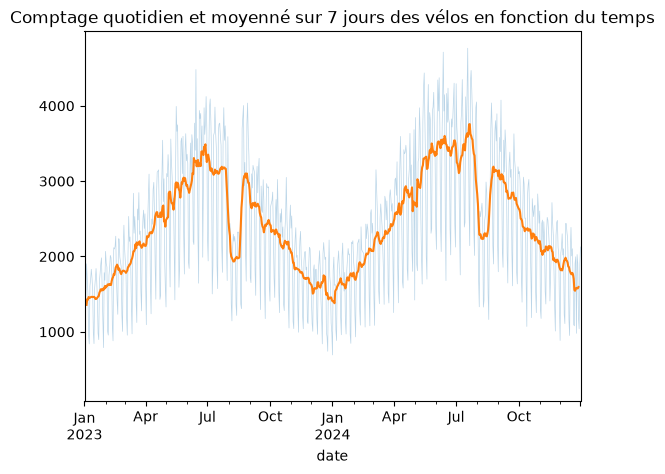

In [136]:
velos.plot(linewidth=0.5, alpha = 0.3)
lisse.plot()
plt.title("Comptage quotidien et moyenné sur 7 jours des vélos en fonction du temps")
plt.show()

In [96]:
assert len(lisse) == 731
assert lisse.isna().sum() == 6
assert abs(lisse.loc["2023-06-15"] - velos.loc["2023-06-12":"2023-06-18"].mean()) < 1e-9
print("ok")

ok


## Exercice 3 – Profils (4 pts)

**3.a** Commençons par le profil hebdomadaire : calculez `profil_semaine`, la moyenne des comptages pour chaque jour de la semaine, avec 0 = lundi … 6 = dimanche. Remplacez ensuite l'index `0..6` par les noms des jours (`"lun"`, `"mar"`, … `"dim"`). De combien (en %) le dimanche est-il plus bas que la moyenne des jours de semaine (lundi à vendredi) ?

In [107]:
# votre code
profil_semaine = velos.groupby(velos.index.dayofweek).mean()
profil_semaine.index = ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]

moy_semaine = profil_semaine.loc["lun":"ven"].mean()
print("Le comptage des vélos le dimanche est en moyenne " + str((1 - profil_semaine["dim"]/moy_semaine) * 100) + "% plus bas que la moyenne des jours de la semaine.")

Le comptage des vélos le dimanche est en moyenne 49.83395691464414% plus bas que la moyenne des jours de la semaine.


In [108]:
assert profil_semaine.shape == (7,)
assert list(profil_semaine.index) == ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]
assert profil_semaine["sam"] < 0.75 * profil_semaine["lun"]
assert profil_semaine["dim"] < profil_semaine["sam"]
print("ok")

ok


````{admonition} Pas encore vu en cours : idxmax et idxmin
:class: note

`serie.idxmax()` renvoie l'**étiquette** de la plus grande valeur (ici un numéro de mois), alors que `serie.max()` renvoie la valeur elle-même ; `idxmin` fait de même pour la plus petite. Sur une série indexée par des dates, on récupère donc directement le `Timestamp` du maximum.
````

**3.b** Intéressons-nous maintenant à la saisonnalité : calculez `profil_mois`, la moyenne pour chaque mois de l'année (1 à 12), les deux années confondues. Quel est le mois le plus chargé ? Et que se passe-t-il en août ?

In [111]:
# votre code
profil_mois = velos.groupby(velos.index.month).mean()
profil_mois

date
1     1547.806452
2     1845.000000
3     2144.024194
4     2585.300000
5     3013.000000
6     3313.183333
7     3285.483871
8     2535.774194
9     2693.766667
10    2309.419355
11    1924.308333
12    1657.911290
dtype: float64

In [203]:
profil_mois.idxmax()

np.int32(6)

Le mois le plus chargé est celui de juin (6) ; en août, les Parisiens partent en partie en vacances.

In [112]:
assert profil_mois.shape == (12,) and list(profil_mois.index) == list(range(1, 13))
assert profil_mois.idxmax() in (6, 7)
assert profil_mois[8] < profil_mois[7] and profil_mois[8] < profil_mois[9]
assert profil_mois.idxmin() in (1, 12)
print("ok")

ok


**3.c** Opposons enfin 2023 à 2024 : avec la sélection par chaîne de date, calculez la moyenne journalière de chaque année, puis la croissance en % de 2023 à 2024 (variable `croissance`). Posez-vous ensuite la même question mois par mois : construisez la table `par_mois` de forme `(12, 2)` (lignes = mois, colonnes = années) — `unstack` peut aider — et repérez le mois où la progression a été la plus forte.

In [118]:
# votre code
moy_2023 = velos.loc['2023'].mean()
moy_2024 = velos.loc['2024'].mean()
moy_2023, moy_2024                      # plus de passage en 2024

(np.float64(2285.9835616438354), np.float64(2525.591530054645))

In [120]:
croissance = (1 - moy_2023/moy_2024)*100
print("Croissance = " + str(croissance) + "%")

Croissance = 9.487201931090784%


In [130]:
par_mois = velos.groupby([velos.index.year, velos.index.month]).mean().unstack(0)
croissance_par_mois = (1 - par_mois[2023]/par_mois[2024])*100
croissance_par_mois

date
1     11.702378
2      9.141010
3      8.100851
4     13.815205
5     10.270265
6      5.292026
7     11.130067
8      6.233824
9     10.996901
10     6.468879
11    10.619767
12    12.374738
dtype: float64

C'est en avril que la croissance entre 2023 et 2024 fut la plus forte (13,8%).

In [131]:
assert 7 < croissance < 14
assert par_mois.shape == (12, 2)
assert list(par_mois.columns) == [2023, 2024]
assert (par_mois[2024] > par_mois[2023]).sum() >= 10
print("ok")

ok


## Exercice 4 – Figure à deux sous-graphiques (3 pts)

Construisez une figure `fig, (ax_haut, ax_bas) = plt.subplots(2, 1, figsize=(11, 8))` :

* en haut : la série journalière `velos` (trait fin, transparent) et la série lissée `lisse` (trait plus épais), avec une légende, un titre et un nom d'axe des ordonnées ;
* en bas : le profil hebdomadaire `profil_semaine` en barres, avec un titre et un nom d'axe des ordonnées.

Terminez par `fig.tight_layout()` et enregistrez dans `serie.png` (`fig.savefig`).

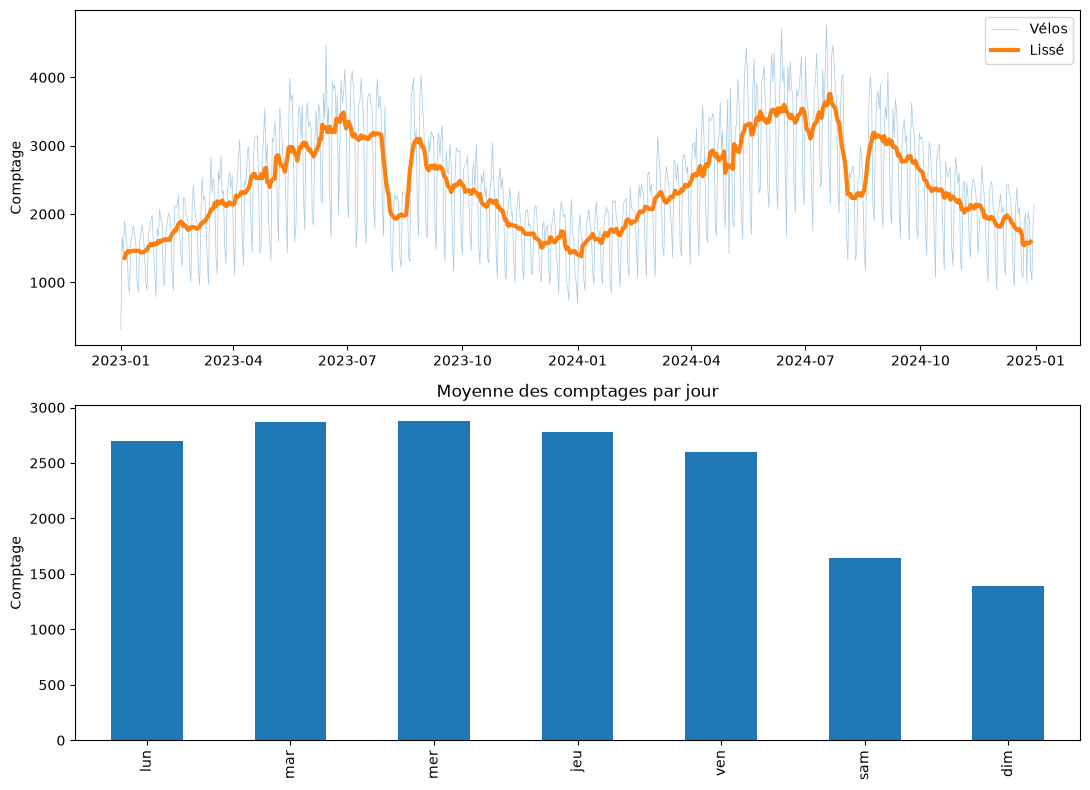

In [166]:
# votre code
fig, (ax_haut, ax_bas) = plt.subplots(2, 1, figsize=(11, 8))
ax_haut.plot(velos, linewidth=0.5, alpha=0.4, label="Vélos")
ax_haut.plot(lisse, linewidth=3, label="Lissé")
ax_haut.set_ylabel("Comptage")
ax_haut.legend()
plt.title("Données de Velos et lisse en fonction du temps")

profil_semaine.plot.bar(ax=ax_bas)
ax_bas.set_ylabel("Comptage")
plt.title("Moyenne des comptages par jour")

fig.tight_layout()
fig.savefig("serie.png")

In [167]:
assert os.path.exists("serie.png")
print("ok")

ok


## Exercice 5 – Question ouverte (3 pts)

C'est ici que vous prenez la main ! Choisissez **une** question sur cette série, puis répondez-y avec une figure (au moins une courbe ou un diagramme, légendée et titrée) et trois lignes de conclusion en Markdown. Voici quelques idées, mais une question à vous est la bienvenue :

* le creux d'août a-t-il la même ampleur en 2023 et en 2024 ?
* l'écart week-end / semaine est-il le même en été et en hiver ?
* quelle semaine de l'année est la plus chargée ? la plus creuse ? est-ce la même les deux années ?
* la croissance entre 2023 et 2024 est-elle uniforme sur l'année, ou concentrée sur certains mois ?
* que se passe-t-il autour des jours fériés que vous connaissez ?

Côté barème, je compte un point pour la pertinence de la méthode, un point pour une figure lisible et correcte, et un point pour une conclusion chiffrée et honnête.

In [208]:
# votre code
# Répondons à la question 3 : quelle semaine de l’année est la plus chargée ? la plus creuse ? est-ce la même les deux années ?

# On réorganise les données ; après lecture de la documentation, la syntaxe avec isocalendar aide
# On enlève aussi la colonne résiduelle

par_semaines = par_semaine.groupby([par_semaine.index.year, par_semaine.index.isocalendar().week]).mean().unstack(0).drop(columns=2025)

par_semaines.idxmax(), par_semaines.idxmin()
par_semaines.max(), par_semaines.min()

(date
 2023    3390.714286
 2024    3589.857143
 dtype: float64,
 date
 2023     879.428571
 2024    1379.714286
 dtype: float64)

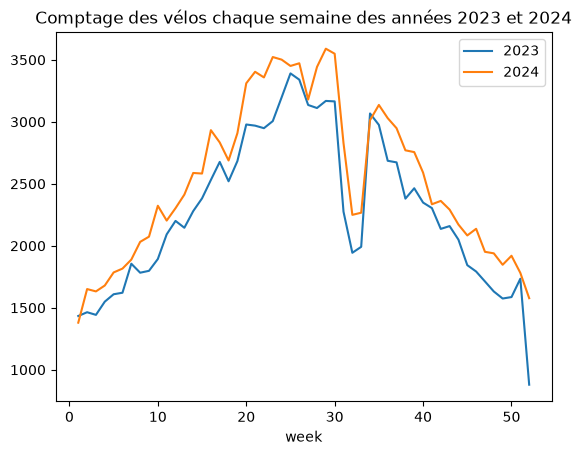

In [199]:
par_semaines[2023].plot()
par_semaines[2024].plot()

plt.legend()
plt.title("Comptage des vélos chaque semaine des années 2023 et 2024")
plt.show()

**Conclusion** : La semaine de l'année la plus chargée est, pour l'année 2023, la 25ème (3391 comptages), et pour 2024 la 29ème (3590 comptages), toutes deux situées pendant l'été (période juin-juillet). Pour les semaines les moins chargées, ce sont deux semaines consécutives : la dernière de 2023 (879 comptages) et la première de 2024 (1380 comptages). Ce ne sont donc pas exactement les mêmes semaines entre les deux années bien qu'elles soient situées dans la même période et que la tendance reste globalement la même. Nous constatons aussi l'effet global de l'augmentation de comptages en 2024 par un relèvement du minimum et du maximum.

## Bonus (+2)

**Bo.1** Quel est le jour le plus creux de toute la série ? Et le plus chargé ? Pour chacun, donnez le jour de la semaine (`.day_name()`) et proposez une explication.

````{admonition} Pas encore vu en cours : pct_change
:class: note

`serie.pct_change()` renvoie la variation *relative* d'une valeur à la suivante : sur `[100, 110, 99]`, elle donne `[NaN, 0.10, -0.10]`. La première case vaut `NaN` faute de valeur précédente, et le résultat est une proportion, à multiplier par 100 pour l'exprimer en pourcentage.
````

**Bo.2** Calculez la croissance annuelle en % à partir des totaux annuels `annuel`. Pourquoi ce chiffre est-il légèrement différent de `croissance` (exercice 3.c) ?

In [214]:
# votre code
# Bo.1
velos.idxmin(), velos.idxmax()

(Timestamp('2023-01-01 00:00:00'), Timestamp('2024-07-18 00:00:00'))

In [215]:
velos.idxmin().day_name(), velos.idxmax().day_name()

('Sunday', 'Thursday')

Le jour avec le moins de comptage est celui du nouvel an de 2023 (un dimanche), et celui avec le plus de passage est le 18 juillet 2024 (un jeudi). D'une part, pour le jour le plus creux, on peut expliquer cette date par l'effet combiné de l'hiver et des fêtes de fin d'année ; pour le jour le plus chargé, l'été est propice aux déplacements à l'extérieur, entre vacanciers et travailleurs (on reste un jeudi).

In [221]:
# Bo.2
croiss_annuelle = (1 - annuel['2023-12-31']/annuel['2024-12-31'])*100
croiss_annuelle, croissance

(np.float64(9.734504658054998), np.float64(9.487201931090784))

Ce chiffre est légèrement différent de `croissance` : en effet, les deux calculs ne sont pas les mêmes, et le fait que `croissance` provienne d'un calcul de moyenne sur d'autres valeurs calculées antérieurement a peut-être créé des approximations.

Bon courage à tous ! Pour toute question sur le sujet, écrivez-moi à [aurelien.noce@minesparis.psl.eu](mailto:aurelien.noce@minesparis.psl.eu), en mettant [aurelien.noce@imagine-app.fr](mailto:aurelien.noce@imagine-app.fr) en copie : la messagerie de l'école perd parfois des mails, la seconde adresse sert de filet.

Au plaisir de vous lire,

votre responsable de cours, Aurélien Noce